# Identification

**Name:** David Rodríguez Fragoso  
**Student ID:** A01748760  
**Course:** TC6035 — Advanced Algorithms and Bioinspired Techniques  
**Problem:** Wireless sensor network placement  
**Instance salt:** 0  
**Route:** Provided mixed discrete–continuous problem

# Formulation


## Decision variables and objective

The deployment is represented by $\mathbf{x}=(\mathbf{z},\mathbf{p})$, with
$\mathbf{z}\in\{0,1\}^{80}$ and $p_i\in[1,c_i]$. The binary variable $z_i$
determines whether site $i$ is active, and $p_i$ sets its transmit power. Powers
assigned to inactive sites are ignored. Candidate coordinates, demand weights
and site-specific caps are fixed by the instance.

The field spans $[0,100]^2$. Demand is sampled at 2,500 points on a $50\times50$
grid covering the entire field. Candidate sites are a separate set of 80 positions.

The objective is maximized:

$$f(\mathbf{x})=C(\mathbf{x})-0.6E(\mathbf{x})-0.25I(\mathbf{x})-P(\mathbf{x}).$$

With $D=\sum_j d_j$, $k_j$ the number of active sensors covering point $j$, and
$n_a=\sum_i z_i$:

$$C=\frac{1}{D}\sum_{j:k_j>0}d_j,\qquad
E=\frac{25n_a+\sum_{i:z_i=1}p_i^2}{15600},\qquad
I=\frac{1}{D}\sum_{j:k_j>0}d_j\left(1-\frac{1}{k_j}\right).$$

Coverage rewards served demand; energy penalizes activation and quadratic power
cost; interference penalizes redundant coverage. All weights and normalization
constants are supplied by the problem and remain unchanged.

## Connectivity and infeasibility

An active sensor covers a disc of radius $r_i=4\sqrt{p_i}$. Active sites $i$ and
$\ell$ communicate if

$$\operatorname{dist}(i,\ell)\leq2.5\min(r_i,r_\ell).$$

A feasible deployment has exactly one connected component. Communication may
use intermediate sensors; direct links between every pair are unnecessary.
For a nonempty deployment with $m$ components:

$$P=\begin{cases}0,&m=1,\\2+0.1(m-1),&m>1.\end{cases}$$

The supplied evaluator separately assigns the empty deployment objective $-2$
and marks it infeasible.

The built-in penalty is used rather than repair. This keeps disconnected
candidates evaluable and provides a component-count penalty during search,
without introducing a repair operator that could change the search behavior.
Feasibility is recorded explicitly alongside the scalar objective.

Power changes coverage, energy, redundancy and communication links. Site
selection changes which power caps and links are available. These mechanisms
motivate an empirical coupling experiment in M0; they do not establish that a
particular hybrid must outperform joint search.


Source: course assignment specification, sections 2–3; `src/tc6035/problem.py` in the course repository.


# Implementations


In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for base in (Path.cwd(), *Path.cwd().parents):
    candidates = (base / "src", base / "tc6035-starter" / "src")
    src = next((p for p in candidates if (p / "tc6035").is_dir()), None)
    if src is not None:
        sys.path.insert(0, str(src))
        break
else:
    raise FileNotFoundError("Keep this notebook inside the course repository.")

from tc6035 import build_instance, SensorPlacementProblem, BudgetExceeded

STUDENT_ID = "A01748760"
SALT = 0
BUDGET = 5_000
SEEDS = tuple(range(30))

instance = build_instance(STUDENT_ID, salt=SALT)
spec = instance.spec

print(f"Python: {platform.python_version()} | NumPy: {np.__version__}")
print(f"Instance: {STUDENT_ID}, salt={SALT}")
print(f"Candidate sites: {instance.n_candidates}")
print(f"Demand points: {instance.n_grid}")
print(f"Power caps: {instance.power_cap.min():.2f}–{instance.power_cap.max():.2f}")
print(f"Final comparison seeds: {SEEDS}")

Python: 3.12.14 | NumPy: 2.3.5
Instance: A01748760, salt=0
Candidate sites: 80
Demand points: 2500
Power caps: 8.84–24.92
Final comparison seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)


In [2]:
def sample_deployment(rng, instance, fraction_range=(0.1, 0.5)):
    fraction = rng.uniform(*fraction_range)
    active = rng.random(instance.n_candidates) < fraction
    power = rng.uniform(instance.spec.power_min, instance.power_cap)
    return active, power


def random_walk(problem, seed, steps=1_000, power_step=3.0):
    rng = np.random.default_rng(seed)
    active, power = sample_deployment(rng, problem.instance)
    values = [problem.evaluate(active, power)]
    n = problem.instance.n_candidates

    for _ in range(steps):
        if rng.random() < 0.5 or not active.any():
            i = rng.integers(n)
            active[i] = ~active[i]
        else:
            i = rng.choice(np.flatnonzero(active))
            power[i] = np.clip(
                power[i] + rng.normal(0, power_step),
                problem.instance.spec.power_min,
                problem.instance.power_cap[i],
            )
        # Every move is accepted: this measures a neighborhood, not an optimizer.
        values.append(problem.evaluate(active, power))

    return np.asarray(values)


def monte_carlo(problem, seed, active_fraction_range=(0.1, 0.5), return_solution=False):
    low, high = active_fraction_range
    if not 0 < low < high < 1:
        raise ValueError("The activation-probability range must be inside (0, 1).")
    if problem.evaluations_remaining < 1:
        raise ValueError("Monte Carlo needs at least one remaining evaluation.")

    rng = np.random.default_rng(seed)
    best_score = -np.inf
    best_active = best_power = best_result = None

    while problem.evaluations_remaining > 0:
        active, power = sample_deployment(rng, problem.instance, active_fraction_range)
        result = problem.evaluate_verbose(active, power)
        if result.objective > best_score:
            best_score = result.objective
            best_active = active.copy()
            best_power = power.copy()
            best_result = result

    if return_solution:
        return float(best_score), best_active, best_power, best_result
    return float(best_score)


ALGORITHMS = {"monte_carlo": monte_carlo}

In [3]:
def accept_annealing(delta, temperature, uniform):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    return delta >= 0 or uniform < np.exp(delta / temperature)


def geometric_temperature(step, total_moves, initial_temperature, final_temperature):
    fraction = step / max(1, total_moves - 1)
    return initial_temperature * (final_temperature / initial_temperature) ** fraction


def simulated_annealing(
    problem, seed, initial_temperature=0.15, final_temperature=1e-4,
    power_step=3.0, flip_probability=0.5, active_fraction=0.3,
    nominal_power=None, mode="joint", initial_active=None, initial_power=None,
    initial_result=None, schedule_moves=None, schedule_offset=0,
    rng=None, return_details=False,
):
    if mode not in ("joint", "discrete", "power"):
        raise ValueError("Unknown search mode.")
    if not 0 < final_temperature < initial_temperature:
        raise ValueError("Require 0 < final temperature < initial temperature.")
    if power_step <= 0 or not 0 <= flip_probability <= 1 or not 0 < active_fraction < 1:
        raise ValueError("Invalid move or initialization parameters.")
    if problem.evaluations_remaining < 1:
        raise ValueError("At least one remaining evaluation is required.")
    inst = problem.instance
    n = inst.n_candidates
    initialization = np.random.default_rng(np.random.SeedSequence([seed, 19_000]))
    rng = np.random.default_rng(seed) if rng is None else rng
    active = (initialization.random(n) < active_fraction if initial_active is None
              else np.asarray(initial_active, dtype=bool).copy())
    if initial_power is None:
        power = (initialization.uniform(inst.spec.power_min, inst.power_cap)
                 if nominal_power is None else np.full(n, float(nominal_power)))
    else:
        power = np.asarray(initial_power, dtype=float).copy()
    if active.shape != (n,) or power.shape != (n,):
        raise ValueError("Initial vectors must match the candidate count.")
    power = np.clip(power, inst.spec.power_min, inst.power_cap)

    used_before = problem.evaluations_used
    current = problem.evaluate_verbose(active, power) if initial_result is None else initial_result
    best_active, best_power, best_result = active.copy(), power.copy(), current
    n_moves = problem.evaluations_remaining
    total_moves = n_moves if schedule_moves is None else schedule_moves
    if n_moves and (total_moves < 1 or schedule_offset < 0 or schedule_offset + n_moves > total_moves):
        raise ValueError("The stage does not fit the declared cooling schedule.")
    log = {"evaluation": [problem.evaluations_used], "temperature": [np.nan],
           "delta": [np.nan], "accepted": [False], "worsening": [False],
           "current_score": [current.objective], "components": [current.n_components],
           "active_count": [current.n_active], "move_kind": ["initial"]}

    for step in range(n_moves):
        temperature = geometric_temperature(
            schedule_offset + step, total_moves, initial_temperature, final_temperature,
        )
        proposed_active, proposed_power = active.copy(), power.copy()
        flip = mode == "discrete" or (mode == "joint" and (
            not active.any() or rng.random() < flip_probability))
        if flip:
            index = rng.integers(n)
            proposed_active[index] = ~proposed_active[index]
            kind = "flip"
        elif active.any():
            index = rng.choice(np.flatnonzero(active))
            proposed_power[index] = np.clip(
                power[index] + rng.normal(0, power_step),
                inst.spec.power_min, inst.power_cap[index],
            )
            kind = "power"
        else:
            kind = "empty-power"
        proposed = problem.evaluate_verbose(proposed_active, proposed_power)
        delta = proposed.objective - current.objective
        uniform = rng.random() if delta < 0 else 0.0
        accepted = accept_annealing(delta, temperature, uniform)
        if accepted:
            active, power, current = proposed_active, proposed_power, proposed
            if current.objective > best_result.objective:
                best_active, best_power = active.copy(), power.copy()
                best_result = current
        for key, value in (
            ("evaluation", problem.evaluations_used), ("temperature", temperature),
            ("delta", delta), ("accepted", accepted), ("worsening", delta < 0),
            ("current_score", current.objective), ("components", current.n_components),
            ("active_count", current.n_active), ("move_kind", kind),
        ):
            log[key].append(value)

    details = {"score": float(best_result.objective), "active": best_active,
               "power": best_power, "result": best_result,
               "log": {k: np.asarray(v) for k, v in log.items()},
               "moves": n_moves, "evaluations_used": problem.evaluations_used - used_before}
    return details if return_details else details["score"]


def joint(seed):
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    result = simulated_annealing(problem, seed, **SA_PARAMS, return_details=True)
    result["record"] = problem.record
    result["phase_counts"] = {"joint": problem.evaluations_used}
    return result


def two_stage(seed):
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    rng = np.random.default_rng(seed)
    schedule_moves = BUDGET - 1
    with problem.limited(BUDGET // 2):
        first = simulated_annealing(
            problem, seed, **SA_PARAMS, mode="discrete", rng=rng,
            schedule_moves=schedule_moves, return_details=True,
        )
    first_used = problem.evaluations_used
    # Reuse the already evaluated boundary state; it is not a free new candidate.
    second = simulated_annealing(
        problem, seed, **SA_PARAMS, mode="power", rng=rng,
        initial_active=first["active"], initial_power=first["power"],
        initial_result=first["result"], schedule_moves=schedule_moves,
        schedule_offset=first["moves"], return_details=True,
    )
    result = dict(second)
    result["log"] = {k: np.concatenate([first["log"][k], second["log"][k][1:]])
                     for k in first["log"]}
    result["record"] = problem.record
    result["phase_counts"] = {"subset": first_used, "power": problem.evaluations_used - first_used}
    result["stage_one_score"] = first["score"]
    return result


def worsening_acceptance(log, budget):
    early = (log["evaluation"] <= 0.1 * budget) & log["worsening"]
    late = (log["evaluation"] > 0.9 * budget) & log["worsening"]
    return {"early_rate": float(log["accepted"][early].mean()) if early.any() else np.nan,
            "late_rate": float(log["accepted"][late].mean()) if late.any() else np.nan,
            "early_worsening": int(early.sum()), "late_worsening": int(late.sum())}


def paired_rank_biserial(a, b):
    from scipy.stats import rankdata
    differences = np.round(np.asarray(a) - np.asarray(b), 12)
    nonzero = differences != 0
    ranks = rankdata(np.abs(differences[nonzero]))
    if not ranks.size:
        return 0.0
    return float((ranks[differences[nonzero] > 0].sum()
                  - ranks[differences[nonzero] < 0].sum()) / ranks.sum())


def holm_correction(p_values):
    ordered = sorted(p_values, key=p_values.get)
    adjusted, running = {}, 0.0
    for i, name in enumerate(ordered):
        running = max(running, (len(ordered) - i) * p_values[name])
        adjusted[name] = min(1.0, running)
    return adjusted


ALGORITHMS["simulated_annealing"] = simulated_annealing


# M0

## Scope of this checkpoint

M0 includes instance characterization, a direct coupling demonstration, held-out nominal-power selection, paired joint–staged search, Monte Carlo and annealing baselines, schedule diagnostics and statistical comparisons. M1–M3 remain pending. Interpretations and AI-ledger verdicts require student review.

## Instance and evaluator checks

These checks use a separate evaluator and do not consume an optimization run budget. The single-sensor result is calculated independently from coordinates and the stated objective.

In [4]:
again = build_instance(STUDENT_ID, salt=SALT)
for name in ("candidates", "power_cap", "grid_points", "demand"):
    assert np.array_equal(getattr(instance, name), getattr(again, name))
assert instance.candidates.shape == (80, 2)
assert instance.grid_points.shape == (2_500, 2)
assert np.all(instance.demand > 0)
assert np.isclose(instance.demand.sum(), 1.0)

# Independent calculation for one active sensor using coordinates and formulas.
probe = SensorPlacementProblem(instance, budget=10, seed=900)
active = np.zeros(80, dtype=bool)
active[0] = True
power = np.full(80, spec.power_min)
power[0] = min(10.0, instance.power_cap[0])
distance = np.linalg.norm(instance.grid_points - instance.candidates[0], axis=1)
manual_coverage = instance.demand[distance <= 4 * np.sqrt(power[0])].sum()
manual_energy = (25 + power[0] ** 2) / 15_600
manual_f = manual_coverage - 0.6 * manual_energy
observed = probe.evaluate_verbose(active, power)
assert observed.feasible and observed.n_components == 1
assert np.isclose(observed.interference, 0)
assert np.isclose(observed.coverage, manual_coverage)
assert np.isclose(observed.energy, manual_energy)
assert np.isclose(observed.objective, manual_f)
print(f"Single-sensor check: manual={manual_f:.8f}, evaluator={observed.objective:.8f}")

# Two distant sensors at minimum power must be disconnected.
a, b = np.unravel_index(np.argmax(instance.dist_between), (80, 80))
assert instance.dist_between[a, b] > 10.0
active[:] = False
active[[a, b]] = True
power[:] = 1.0
observed = probe.evaluate_verbose(active, power)
manual_f = observed.coverage - 0.6 * observed.energy - 0.25 * observed.interference - 2.1
assert not observed.feasible and observed.n_components == 2
assert np.isclose(observed.objective, manual_f)

# Above-cap requests must have the same result as capped requests.
above = probe.evaluate(active, np.full(80, 100.0))
capped = probe.evaluate(active, instance.power_cap)
assert np.isclose(above, capped)

budget_probe = SensorPlacementProblem(instance, budget=2, seed=900)
budget_probe.evaluate_batch(np.stack([active, active]), np.stack([power, power]))
assert budget_probe.evaluations_used == 2
try:
    budget_probe.evaluate(active, power)
except BudgetExceeded:
    pass
else:
    raise AssertionError("The evaluator accepted an over-budget evaluation.")
assert len(budget_probe.record.values) == budget_probe.evaluations_used == 2
print("Determinism, connectivity penalty, caps and budget checks passed.")
INSTANCE_CHECK_EVALUATIONS = probe.evaluations_used + budget_probe.evaluations_used
print(f"Verification evaluations: {INSTANCE_CHECK_EVALUATIONS}")

Single-sensor check: manual=0.14584294, evaluator=0.14584294
Determinism, connectivity penalty, caps and budget checks passed.
Verification evaluations: 6


## Instance geometry and demand

The heatmap covers the full 100 by 100 field. Circles mark candidate locations, not demand points; circle size represents the site-specific power cap, not a coverage radius.

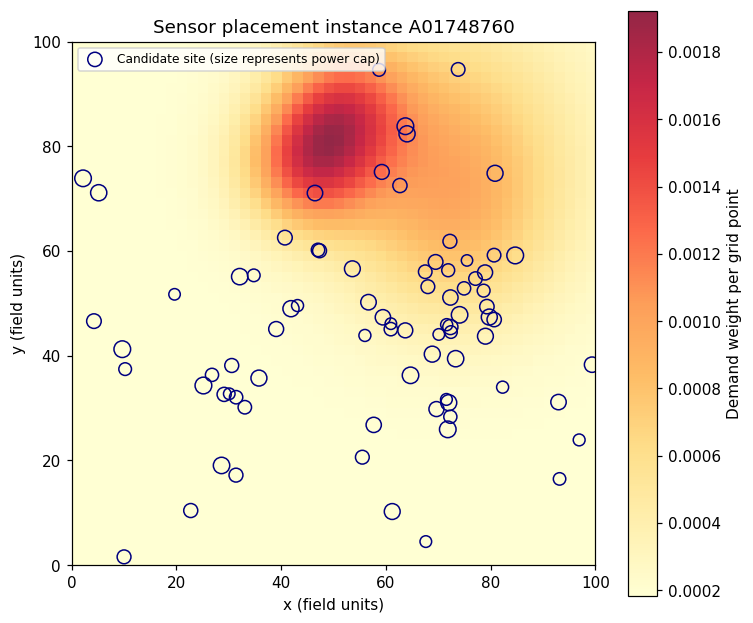

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
g = spec.grid_size
image = ax.imshow(
    instance.demand.reshape(g, g).T,
    origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.85,
)
ax.scatter(
    instance.candidates[:, 0], instance.candidates[:, 1],
    s=20 + 100 * instance.power_cap / spec.power_max,
    facecolors="none", edgecolors="navy", linewidths=1,
    label="Candidate site (size represents power cap)",
)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
ax.set(xlabel="x (field units)", ylabel="y (field units)",
       title=f"Sensor placement instance {STUDENT_ID}", aspect="equal")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## Feasibility under random sampling

For each of 2,000 deployments, an activation probability is drawn uniformly from [0.1, 0.5], then each site is independently activated with that probability. Each power is drawn uniformly from [1, its own cap]. This characterizes the sampling distribution; it is separate from final optimizer runs.

In [6]:
CHAR_SEED = 10_000
N_DEPLOYMENTS = 2_000
rng = np.random.default_rng(CHAR_SEED)
characterization = SensorPlacementProblem(instance, budget=N_DEPLOYMENTS, seed=CHAR_SEED)
feasible_flags = []
component_counts = []
active_counts = []
sample_scores = []

for _ in range(N_DEPLOYMENTS):
    active, power = sample_deployment(rng, instance)
    result = characterization.evaluate_verbose(active, power)
    feasible_flags.append(result.feasible)
    component_counts.append(result.n_components)
    active_counts.append(result.n_active)
    sample_scores.append(result.objective)

feasible_flags = np.asarray(feasible_flags)
component_counts = np.asarray(component_counts)
active_counts = np.asarray(active_counts)
sample_scores = np.asarray(sample_scores)
feasible_fraction = float(feasible_flags.mean())
assert characterization.evaluations_used == N_DEPLOYMENTS

print(f"Feasible deployments: {feasible_flags.sum()}/{N_DEPLOYMENTS} ({feasible_fraction:.2%})")
print(f"Median active count: {np.median(active_counts):.1f}")
print(f"Median component count: {np.median(component_counts):.1f}")
print(f"Characterization evaluations: {characterization.evaluations_used}")

Feasible deployments: 330/2000 (16.50%)
Median active count: 24.0
Median component count: 3.0
Characterization evaluations: 2000


## Random-walk autocorrelation

The walk makes 1,000 moves and accepts every move. With probability 0.5 it flips one uniformly selected activation bit; otherwise it perturbs the power of a uniformly selected active sensor with Gaussian standard deviation 3, clipped to its bounds. An empty deployment forces a flip. The initial evaluation costs one additional call. This diagnostic depends on both the neighborhood and the sampled trajectory.

Lag-1 autocorrelation: 0.9353
Walk evaluations: 1001 (initial state + 1000 moves)


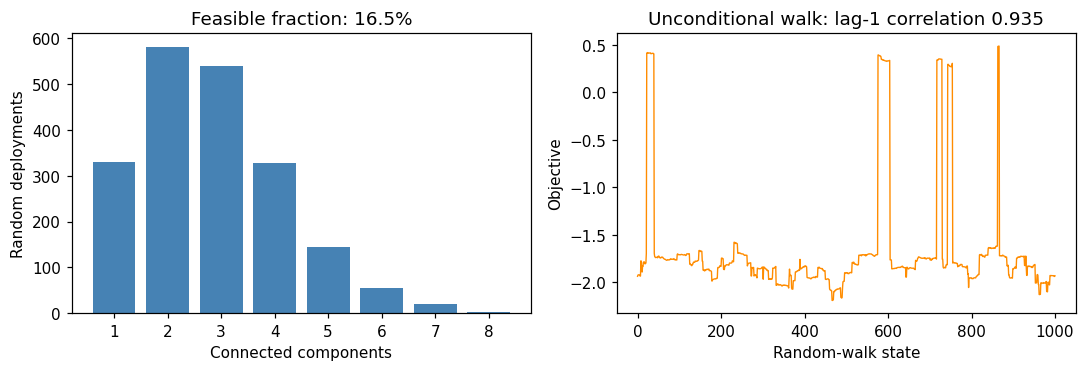

In [7]:
WALK_SEED = 10_001
WALK_STEPS = 1_000
WALK_POWER_STEP = 3.0
walk_problem = SensorPlacementProblem(instance, budget=WALK_STEPS + 1, seed=WALK_SEED)
walk_values = random_walk(walk_problem, WALK_SEED, WALK_STEPS, WALK_POWER_STEP)

assert walk_problem.evaluations_used == WALK_STEPS + 1
assert np.std(walk_values[:-1]) > 0 and np.std(walk_values[1:]) > 0
rho_1 = float(np.corrcoef(walk_values[:-1], walk_values[1:])[0, 1])

print(f"Lag-1 autocorrelation: {rho_1:.4f}")
print(f"Walk evaluations: {walk_problem.evaluations_used} (initial state + {WALK_STEPS} moves)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
components, frequencies = np.unique(component_counts, return_counts=True)
axes[0].bar(components, frequencies, color="steelblue")
axes[0].set(xlabel="Connected components", ylabel="Random deployments",
            title=f"Feasible fraction: {feasible_fraction:.1%}")
axes[0].set_xticks(components)
axes[1].plot(np.arange(walk_values.size), walk_values, lw=0.9, color="darkorange")
axes[1].set(xlabel="Random-walk state", ylabel="Objective",
            title=f"Unconditional walk: lag-1 correlation {rho_1:.3f}")
fig.tight_layout()
plt.show()

## Preliminary interpretation

The feasible fraction describes how often connected deployments appeared under the declared random-sampling procedure. It is not the fraction of all possible deployments that are feasible, and it may change with the activation and power distributions.

The measured lag-1 autocorrelation indicates a strong positive relationship between consecutive objective values in this walk: values above the trajectory mean tend to be followed by above-mean values, and below-mean values tend to be followed by below-mean values. The current value therefore carries information about the next one, but the correlation is not a prediction-accuracy percentage and does not mean that moves usually improve the objective.

This observation motivates testing whether neighborhood-based methods can exploit local structure. It does not establish that optimization will be easy or that any method will outperform Monte Carlo. The estimate depends on the move operator, step size and sampled trajectory; transitions between connected and disconnected deployments can also influence it through the penalty.

These are initial characterization results. Later sections will examine whether the proposed methods exploit this structure under the evaluation budget. Their convergence traces, internal-state diagnostics and paired comparisons will provide the evidence for the final analysis.


In [8]:
print(
    f"Under the declared random-deployment distribution, {feasible_fraction:.1%} "
    "of sampled deployments were connected. This is distribution-specific, "
    "not the fraction of all possible deployments that are feasible."
)
print(
    f"The lag-1 correlation was {rho_1:.3f} for the declared move operator and seed. "
    "It describes this walk; it does not establish global smoothness, "
    "unimodality or optimizer superiority."
)
print("The diagnostics above are characterization, not 30-seed optimizer results.")

Under the declared random-deployment distribution, 16.5% of sampled deployments were connected. This is distribution-specific, not the fraction of all possible deployments that are feasible.
The lag-1 correlation was 0.935 for the declared move operator and seed. It describes this walk; it does not establish global smoothness, unimodality or optimizer superiority.
The diagnostics above are characterization, not 30-seed optimizer results.


## Why this instance is difficult

Even before assigning power, the 80 activation decisions define $2^{80} \approx 1.21\times10^{24}$ possible subsets. Each subset also admits continuous power assignments, so exhaustive enumeration is not a practical approach.

The two decision layers interact. Changing power affects coverage, energy, redundant coverage and communication links. Activating or removing a sensor changes the contribution of the remaining sensors, even when their powers stay fixed. Different site locations and power caps also mean that one candidate cannot simply replace another.

The objective contains competing effects: more power may cover additional demand and connect the network, but increases quadratic energy cost and may add redundant coverage. Removing an overlapping sensor may save energy, yet lose demand that only it serves or remove a communication bridge. A locally attractive change can therefore reduce the overall objective.

Connectivity introduces abrupt changes. A small power reduction can remove a critical link, split the deployment into multiple components and trigger a large penalty. Coverage is also evaluated at discrete grid points, so a small radius change may reach no new point or cross one or more coverage thresholds.

The characterization provides instance-specific evidence. Only 16.5% of the 2,000 deployments generated by the declared sampling procedure were connected. The random walk had lag-1 autocorrelation of approximately 0.935, indicating local dependence under its chosen moves rather than an entirely unstructured objective. This does not establish that global optimization is easy: the estimate depends on the move operator and trajectory, and connectivity penalties contribute to it. The number and quality of local optima have not been established by these diagnostics.


## Coupling: design stated before results

A controlled two-site example first tests whether changing power alone can change feasibility. The stochastic study then compares two ways of organizing the same annealing engine. It measures the consequences of the selected layer schedule; it is not a proof that every staged algorithm is inferior.

`joint(seed)` may flip activation bits or perturb active-sensor powers throughout the budget. `two_stage(seed)` first searches activation at fixed nominal power for 2,500 evaluations, then searches power on its selected subset for the remaining 2,500. Both start from exactly the same seed-specific deployment, use the same move scales, and follow one global geometric cooling schedule across 4,999 proposals. Stage two starts from the best evaluated stage-one state and reuses its known score. This costs no new evaluation because it is the same state, and the next power proposal is charged normally. The temperature is not reset at the stage boundary.

The expected limitation of staging is that a subset chosen at one nominal power cannot be reconsidered after power tuning. Joint search can revisit either layer, but might spend evaluations less efficiently. Either outcome is admissible. Only the nominal-power pilot uses separate tuning seeds; final comparisons use seeds 0–29.

In [9]:
SA_BASE_PARAMS = {
    "initial_temperature": 0.15,
    "final_temperature": 1e-4,
    "power_step": 3.0,
    "flip_probability": 0.5,
    "active_fraction": 0.3,
}
print(SA_BASE_PARAMS)

{'initial_temperature': 0.15, 'final_temperature': 0.0001, 'power_step': 3.0, 'flip_probability': 0.5, 'active_fraction': 0.3}


### Verify the reusable search engine

The checks cover the maximization sign, known acceptance probabilities, cooling endpoints, best-versus-current state, fixed-layer invariants, exact budgets and repeatability. A scripted objective with known scores tests rejection behavior; those synthetic scores are not sensor-placement results. A small staged audit checks one evaluation counter, cached boundary-state reuse and an identical temperature timeline.

In [10]:
# Acceptance is checked against known probabilities, not only a completed run.
assert accept_annealing(1.0, 0.1, 0.999)
assert accept_annealing(0.0, 0.1, 0.999)
assert accept_annealing(-1.0, 1.0, 0.2)
assert not accept_annealing(-1.0, 1.0, 0.5)
assert not accept_annealing(-1.0, 0.01, 0.2)
assert np.isclose(geometric_temperature(0, 4_999, 0.15, 1e-4), 0.15)
assert np.isclose(geometric_temperature(4_998, 4_999, 0.15, 1e-4), 1e-4)

from types import SimpleNamespace


class ScriptedProblem:
    def __init__(self):
        self.instance = SimpleNamespace(n_candidates=2, power_cap=np.array([5., 5.]),
                                        spec=SimpleNamespace(power_min=1.))
        self.budget, self.evaluations_used = 4, 0
        self.scores = [0., 1., -1., 2.]

    @property
    def evaluations_remaining(self):
        return self.budget - self.evaluations_used

    def evaluate_verbose(self, active, power):
        score = self.scores[self.evaluations_used]
        self.evaluations_used += 1
        return SimpleNamespace(objective=score, n_components=1, n_active=int(active.sum()))


scripted = simulated_annealing(
    ScriptedProblem(), 7, initial_temperature=1., final_temperature=0.01,
    initial_active=np.ones(2, dtype=bool), initial_power=np.ones(2) * 2,
    mode="power", return_details=True,
)
assert np.array_equal(scripted["log"]["current_score"], [0., 1., 1., 2.])
assert scripted["score"] == 2.


class AuditedProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.candidates_seen = []

    def evaluate_verbose(self, active, power):
        self.candidates_seen.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


sa_check_problems = []
initial_active = np.zeros(80, dtype=bool)
initial_active[:20] = True
initial_power = np.minimum(np.full(80, 12.), instance.power_cap)

for mode in ("discrete", "power", "joint"):
    probe = AuditedProblem(instance, budget=37, seed=20_100)
    result = simulated_annealing(
        probe, 20_100, **SA_BASE_PARAMS, mode=mode,
        initial_active=initial_active, initial_power=initial_power, return_details=True,
    )
    sa_check_problems.append(probe)
    assert probe.evaluations_used == len(probe.record.values) == 37
    assert result["score"] == max(probe.record.values) == probe.record.best
    for a, p in probe.candidates_seen:
        assert np.all((p >= 1) & (p <= instance.power_cap))
        if mode == "discrete":
            assert np.array_equal(p, initial_power)
        elif mode == "power":
            assert np.array_equal(a, initial_active)
    score_check = SensorPlacementProblem(instance, budget=1, seed=20_100)
    assert np.isclose(score_check.evaluate(result["active"], result["power"]), result["score"])
    sa_check_problems.append(score_check)

repeat = SensorPlacementProblem(instance, budget=37, seed=20_100)
simulated_annealing(repeat, 20_100, **SA_BASE_PARAMS, mode="joint",
                    initial_active=initial_active, initial_power=initial_power)
assert np.array_equal(repeat.record.values, probe.record.values)
sa_check_problems.append(repeat)

# Audit a miniature staged run, including its boundary-state reuse and schedule.
original_problem_class, original_budget = SensorPlacementProblem, BUDGET
audits = []


class PhaseAudit(AuditedProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        audits.append(self)


try:
    SensorPlacementProblem, BUDGET = PhaseAudit, 40
    SA_PARAMS = {**SA_BASE_PARAMS, "nominal_power": 12.}
    checked_joint, checked_staged = joint(20_101), two_stage(20_101)
finally:
    SensorPlacementProblem, BUDGET = original_problem_class, original_budget

assert checked_staged["phase_counts"] == {"subset": 20, "power": 20}
assert checked_staged["record"].evaluations_used == checked_joint["record"].evaluations_used == 40
assert np.allclose(checked_joint["log"]["temperature"], checked_staged["log"]["temperature"], equal_nan=True)
assert checked_staged["score"] == checked_staged["record"].best
assert np.array_equal(audits[0].candidates_seen[0][0], audits[1].candidates_seen[0][0])
assert np.array_equal(audits[0].candidates_seen[0][1], audits[1].candidates_seen[0][1])
assert all(np.array_equal(a, checked_staged["active"]) for a, _ in audits[1].candidates_seen[20:])
sa_check_problems.extend(audits)
assert np.isclose(paired_rank_biserial([2, 3], [0, 1]), 1.)
assert np.isclose(paired_rank_biserial([0, 1], [2, 3]), -1.)
assert paired_rank_biserial([1, 1], [1, 1]) == 0.
adjusted_check = holm_correction({"a": 0.01, "b": 0.04})
assert np.isclose(adjusted_check["a"], 0.02) and np.isclose(adjusted_check["b"], 0.04)
SA_CHECK_EVALUATIONS = sum(p.evaluations_used for p in sa_check_problems)
print("SA checks passed: maximization sign, rejection, cooling endpoints, fixed layers, best state and budgets.")
print("Staged audit: shared initialization and cooling schedule, one counter, 20 + 20 evaluations.")
print(f"Real verification evaluations: {SA_CHECK_EVALUATIONS}; scripted scores are not experimental data.")


SA checks passed: maximization sign, rejection, cooling endpoints, fixed layers, best state and budgets.
Staged audit: shared initialization and cooling schedule, one counter, 20 + 20 evaluations.
Real verification evaluations: 231; scripted scores are not experimental data.


### Direct demonstration on this instance

Two sites are selected whose separation exceeds their communication range at minimum power but is reachable at their own caps. Their activation mask remains unchanged. Two counted evaluations test the predicted change in component count. This deterministic demonstration is separate from the 30-seed optimizer comparison.

In [11]:
# A deterministic counterexample: fixed activation, different connectivity.
distances = instance.dist_between
maximum_link = 10 * np.sqrt(np.minimum(instance.power_cap[:, None], instance.power_cap[None, :]))
eligible_pairs = np.argwhere(np.triu((distances > 10) & (distances <= maximum_link), k=1))
assert eligible_pairs.size
pair = eligible_pairs[0]
probe_active = np.zeros(instance.n_candidates, dtype=bool)
probe_active[pair] = True
coupling_probe = SensorPlacementProblem(instance, budget=2, seed=30_000)
probe_low = coupling_probe.evaluate_verbose(probe_active, np.ones(instance.n_candidates))
probe_high = coupling_probe.evaluate_verbose(probe_active, instance.power_cap)
assert probe_low.n_components == 2 and not probe_low.feasible
assert probe_high.n_components == 1 and probe_high.feasible
COUPLING_PROBE_EVALUATIONS = coupling_probe.evaluations_used
print(f"Fixed active site indices (zero-based): {pair.tolist()}")
print(f"Distance between sites: {distances[tuple(pair)]:.3f}")
print(f"Power 1 at both: components={probe_low.n_components}, feasible={probe_low.feasible}, objective={probe_low.objective:.6f}")
print(f"Site caps {instance.power_cap[pair]}: components={probe_high.n_components}, feasible={probe_high.feasible}, objective={probe_high.objective:.6f}")
print(f"Controlled demonstration evaluations: {COUPLING_PROBE_EVALUATIONS}")


Fixed active site indices (zero-based): [0, 1]
Distance between sites: 36.116
Power 1 at both: components=2, feasible=False, objective=-2.085691
Site caps [18.58650087 22.25593769]: components=1, feasible=True, objective=0.320764
Controlled demonstration evaluations: 2


### Select the nominal power without using final seeds

Candidate nominal powers are 8, 12, 16 and 20, spanning low-to-high powers and including values affected by heterogeneous caps. Each candidate receives 30 discrete-only pilot runs, seeds 100–129, capped at 1,000 evaluations each. These are explicitly separate tuning costs. The candidate with the largest median penalized objective is selected; an exact tie favors lower nominal power. Final seeds are not consulted. This coarse pilot supports a practical choice, not a claim that the selected power is globally optimal or significantly superior to all alternatives.

In [12]:
from tc6035.runlog import RunSet, save_runset

NOMINAL_CANDIDATES = (8., 12., 16., 20.)
TUNING_SEEDS = tuple(range(100, 130))
TUNING_BUDGET = 1_000
assert set(TUNING_SEEDS).isdisjoint(SEEDS)
nominal_scores, nominal_connected = {}, {}

for nominal in NOMINAL_CANDIDATES:
    records, scores, connected = [], [], []
    for seed in TUNING_SEEDS:
        problem = SensorPlacementProblem(instance, budget=TUNING_BUDGET, seed=seed)
        result = simulated_annealing(
            problem, seed, **SA_BASE_PARAMS, nominal_power=nominal,
            mode="discrete", return_details=True,
        )
        assert problem.evaluations_used == TUNING_BUDGET
        records.append(problem.record)
        scores.append(result["score"])
        connected.append(result["result"].feasible)
    nominal_scores[nominal] = np.array(scores)
    nominal_connected[nominal] = int(np.sum(connected))
    save_runset(
        f"results/m0_nominal_{int(nominal)}.npz",
        RunSet(algorithm="nominal_power_tuning", student_id=STUDENT_ID,
               params={**SA_BASE_PARAMS, "nominal_power": nominal, "mode": "discrete",
                       "salt": SALT}, records=records),
    )
    q1, med, q3 = np.percentile(scores, [25, 50, 75])
    print(f"Nominal {nominal:4.0f}: median={med:.6f}, Q1–Q3=[{q1:.6f}, {q3:.6f}], connected={sum(connected)}/30", flush=True)

NOMINAL_POWER = max(NOMINAL_CANDIDATES,
                    key=lambda p: (np.median(nominal_scores[p]), -p))
SA_PARAMS = {**SA_BASE_PARAMS, "nominal_power": NOMINAL_POWER}
NOMINAL_TUNING_EVALUATIONS = len(NOMINAL_CANDIDATES) * len(TUNING_SEEDS) * TUNING_BUDGET
print(f"Selected NOMINAL_POWER = {NOMINAL_POWER:g}; largest pilot median, lower value breaks an exact tie.")
print(f"Separate tuning evaluations: {NOMINAL_TUNING_EVALUATIONS:,}")


Nominal    8: median=0.629759, Q1–Q3=[0.628075, 0.633448], connected=30/30
Nominal   12: median=0.656091, Q1–Q3=[0.648340, 0.659988], connected=30/30
Nominal   16: median=0.660115, Q1–Q3=[0.655122, 0.666064], connected=30/30
Nominal   20: median=0.672674, Q1–Q3=[0.665977, 0.677270], connected=30/30
Selected NOMINAL_POWER = 20; largest pilot median, lower value breaks an exact tie.
Separate tuning evaluations: 120,000


### Thirty paired seeds: joint versus staged search

For each seed, the final objective from joint search is compared with the final objective from staged search. Both runs start from the same deployment and receive 5,000 evaluations. The joint runs are also reused as the standalone annealing runs in the later Monte Carlo comparison; they are not executed or counted twice.

Read the results in this order:

1. **Wins, ties and losses:** how many seeds favor each method.
2. **Median paired difference:** subtract the staged score from the joint score for each seed, then take the median of those 30 differences. This expresses the typical observed advantage in objective units.
3. **Wilcoxon signed-rank test:** examines whether the paired differences provide evidence of a systematic difference, considering their signs and ranks. A small p-value is evidence against the test's no-difference model under its assumptions; it is not the probability that one algorithm is better.
4. **Holm correction:** adjusts the p-values for the two planned M0 comparisons to control the increased chance of false-positive conclusions from multiple tests.
5. **Paired rank-biserial correlation:** an additional effect-size measure based on the balance of positive and negative signed ranks. It ranges from -1 to +1; positive values favor the first method, and +1 means every nonzero paired difference favors it. It is not a percentage improvement. The assignment requires an effect size; this particular measure is an analysis choice, not a separately mandated course requirement.

The median paired difference and the win count are the most direct descriptions of the observed advantage. The statistical test and supplementary effect measure support the interpretation rather than replace it. The paired rank-biserial measure is documented in the [effectsize reference](https://easystats.github.io/effectsize/reference/rank_biserial.html).

Both tests are two-sided. Differences are rounded to 12 decimal places only for statistical ranking to avoid ranking floating-point noise; recorded objectives remain full precision. Holm-adjusted results for both planned comparisons are reported after the SA–Monte Carlo comparison.


In [13]:
from time import perf_counter
from scipy.stats import wilcoxon

joint_results, staged_results = [], []
coupling_seconds = []
for i, seed in enumerate(SEEDS):
    started = perf_counter()
    together, staged = joint(seed), two_stage(seed)
    for result in (together, staged):
        assert result["record"].evaluations_used == len(result["record"].values) == BUDGET
        assert result["score"] == result["record"].best
    assert staged["phase_counts"] == {"subset": BUDGET // 2, "power": BUDGET - BUDGET // 2}
    assert np.isclose(together["log"]["current_score"][0], staged["log"]["current_score"][0])
    assert np.allclose(together["log"]["temperature"], staged["log"]["temperature"], equal_nan=True)
    joint_results.append(together)
    staged_results.append(staged)
    coupling_seconds.append(perf_counter() - started)
    if (i + 1) % 5 == 0:
        print(f"Coupling: {i + 1}/{len(SEEDS)} paired seeds complete", flush=True)

joint_scores = np.array([r["score"] for r in joint_results])
staged_scores = np.array([r["score"] for r in staged_results])
joint_records = [r["record"] for r in joint_results]
staged_records = [r["record"] for r in staged_results]

for name, records in (("joint", joint_records), ("two_stage", staged_records)):
    save_runset(
        f"results/m0_{name}.npz",
        RunSet(algorithm=name, student_id=STUDENT_ID,
               params={**SA_PARAMS, "salt": SALT, "split": 0.5 if name == "two_stage" else None,
                       "cooling": "one global geometric schedule"}, records=records),
    )

coupling_differences = np.round(joint_scores - staged_scores, 12)
coupling_test = wilcoxon(coupling_differences, alternative="two-sided", method="auto") if np.any(coupling_differences) else None
p_coupling = float(coupling_test.pvalue) if coupling_test else 1.0
coupling_effect = paired_rank_biserial(joint_scores, staged_scores)
coupling_median_difference = float(np.median(joint_scores - staged_scores))

for name, scores in (("Joint", joint_scores), ("Two-stage", staged_scores)):
    q1, med, q3 = np.percentile(scores, [25, 50, 75])
    print(f"{name}: median={med:.6f}, Q1–Q3=[{q1:.6f}, {q3:.6f}], IQR={q3-q1:.6f}")
print(f"Joint wins/ties/losses: {(coupling_differences > 0).sum()}/{(coupling_differences == 0).sum()}/{(coupling_differences < 0).sum()}")
print(f"Median paired difference (joint minus staged): {coupling_median_difference:+.6f}")
print(f"Wilcoxon raw p={p_coupling:.6g}; paired rank-biserial effect={coupling_effect:+.4f}")
print("Holm adjustment across the two planned M0 tests is reported after the SA–Monte Carlo comparison.")
print("Per staged run: 2,500 subset evaluations + 2,500 power evaluations; one evaluator.")


Coupling: 5/30 paired seeds complete
Coupling: 10/30 paired seeds complete
Coupling: 15/30 paired seeds complete
Coupling: 20/30 paired seeds complete
Coupling: 25/30 paired seeds complete
Coupling: 30/30 paired seeds complete
Joint: median=0.714655, Q1–Q3=[0.712220, 0.717910], IQR=0.005690
Two-stage: median=0.687170, Q1–Q3=[0.679718, 0.696354], IQR=0.016636
Joint wins/ties/losses: 27/0/3
Median paired difference (joint minus staged): +0.027689
Wilcoxon raw p=0.000110582; paired rank-biserial effect=+0.7591
Holm adjustment across the two planned M0 tests is reported after the SA–Monte Carlo comparison.
Per staged run: 2,500 subset evaluations + 2,500 power evaluations; one evaluator.


## Monte Carlo baseline

Each evaluation samples a fresh activation vector and power vector independently of previous samples, scores the complete deployment and retains the best solution found. A run uses exactly 5,000 evaluations, including every rejected or infeasible sample. The baseline uses the 30 declared seeds and no objective calls outside the instrumented evaluator.

An activation probability is sampled uniformly from [0.1, 0.5] for each deployment; sites are activated independently conditional on that probability. This covers expected deployment sizes from 8 to 40, spanning sparse and denser deployments without fixing one cardinality. It is the course's suggested starting range and matches the feasibility diagnostic. No range tuning has been performed. Extreme cardinalities remain possible but receive less sampling effort; the induced distribution is not uniform over all binary vectors. Powers are uniform within each site's own bounds.

The method returns the largest penalized objective, not the last evaluated score. Stored best vectors and objective components come from an already counted evaluation; reporting them spends no extra evaluations.

### Implementation checks

Small separate runs verify exact budget use, replay the same candidates independently, check the retained maximum and vectors, and verify seeded repeatability. These evaluations are reported separately from the baseline runs.

In [14]:
CHECK_SEED = 20_000
CHECK_BUDGET = 37
check_a = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
check_score, check_active, check_power, check_result = monte_carlo(
    check_a, CHECK_SEED, return_solution=True,
)

# Independent replay: sample the candidates and explicitly take their maximum.
check_b = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
replay_rng = np.random.default_rng(CHECK_SEED)
replay_scores = []
for _ in range(CHECK_BUDGET):
    active, power = sample_deployment(replay_rng, instance)
    replay_scores.append(check_b.evaluate(active, power))

assert np.isclose(check_score, max(replay_scores))
assert np.array_equal(check_a.record.values, check_b.record.values)
assert np.array_equal(check_a.record.best_so_far, np.maximum.accumulate(replay_scores))
assert check_a.evaluations_used == check_b.evaluations_used == CHECK_BUDGET
assert check_active.dtype == bool and check_active.shape == (80,)
assert np.all((check_power >= spec.power_min) & (check_power <= instance.power_cap))

# The returned vectors must reproduce the saved best result in a separate check.
solution_probe = SensorPlacementProblem(instance, budget=1, seed=CHECK_SEED)
assert np.isclose(solution_probe.evaluate(check_active, check_power), check_score)

repeat_probe = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
assert monte_carlo(repeat_probe, CHECK_SEED) == check_score
assert np.array_equal(repeat_probe.record.values, check_a.record.values)
MC_CHECK_EVALUATIONS = 3 * CHECK_BUDGET + 1
print("Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.")
print(f"Separate verification evaluations: {MC_CHECK_EVALUATIONS}")

Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.
Separate verification evaluations: 112


### Thirty-seed experiment

Each seed starts a fresh evaluator on the same instance. Run traces are saved locally for later comparisons and are not separate submission files. The returned score is checked against both the recorded best and the maximum evaluated value.

In [15]:
from time import perf_counter
from tc6035.runlog import RunSet, save_runset

MC_PARAMS = {"active_fraction_range": (0.1, 0.5)}
mc_records, mc_solutions = [], []
mc_run_seconds = []

for i, seed in enumerate(SEEDS):
    prob = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    started = perf_counter()
    score, active, power, result = monte_carlo(
        prob, seed, **MC_PARAMS, return_solution=True,
    )
    mc_run_seconds.append(perf_counter() - started)
    assert prob.evaluations_used == len(prob.record.values) == BUDGET
    assert score == prob.record.best == max(prob.record.values)
    mc_records.append(prob.record)
    mc_solutions.append((active, power, result))
    if (i + 1) % 5 == 0:
        print(f"Monte Carlo: {i + 1}/{len(SEEDS)} seeds complete", flush=True)

mc_scores = np.array([record.best for record in mc_records])
MC_BASELINE_MEDIAN = float(np.median(mc_scores))
MC_Q1, MC_Q3 = np.percentile(mc_scores, [25, 75])
MC_IQR = float(MC_Q3 - MC_Q1)
mc_used = np.array([record.evaluations_used for record in mc_records])
mc_feasible_bests = sum(result.feasible for _, _, result in mc_solutions)

save_runset(
    "results/m0_monte_carlo.npz",
    RunSet(algorithm="monte_carlo", student_id=STUDENT_ID,
           params={**MC_PARAMS, "salt": SALT}, records=mc_records),
)

print(f"Seeds: {SEEDS}")
print(f"Median final objective: {MC_BASELINE_MEDIAN:.6f}")
print(f"Q1–Q3: [{MC_Q1:.6f}, {MC_Q3:.6f}] | IQR width: {MC_IQR:.6f}")
print(f"Connected best solutions: {mc_feasible_bests}/{len(SEEDS)}")
print(f"Evaluations per run: min={mc_used.min()}, max={mc_used.max()}")
print(f"Total baseline evaluations: {mc_used.sum():,}")
print(f"Median runtime per run: {np.median(mc_run_seconds):.2f} seconds")

Monte Carlo: 5/30 seeds complete
Monte Carlo: 10/30 seeds complete
Monte Carlo: 15/30 seeds complete
Monte Carlo: 20/30 seeds complete
Monte Carlo: 25/30 seeds complete
Monte Carlo: 30/30 seeds complete
Seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)
Median final objective: 0.551577
Q1–Q3: [0.540722, 0.561175] | IQR width: 0.020453
Connected best solutions: 30/30
Evaluations per run: min=5000, max=5000
Total baseline evaluations: 150,000
Median runtime per run: 1.13 seconds


### Baseline convergence and variation

The full view retains the initial negative scores, which arise from disconnected sampled deployments. A second view enlarges evaluations 100–5,000 with vertical limits derived from the same median and quartile data; it introduces no additional run or resampling. The band shows Q1–Q3 of the 30 best-so-far traces at each evaluation. The curve is a pointwise median across runs, not the trajectory of one seed.

The final-score scatter shows one retained best value per seed after 5,000 evaluations. Its vertical scale differs because it contains only final scores. The expanded view and printed checkpoints expose later improvements hidden by the full vertical range. These figures do not by themselves establish convergence to an optimum or replace later mechanism-specific diagnostics.


Median best at evaluation 100: 0.494076
Median best at evaluation 1,000: 0.533529
Median best at evaluation 5,000: 0.551577
Runs improving after evaluation 1,000: 27/30


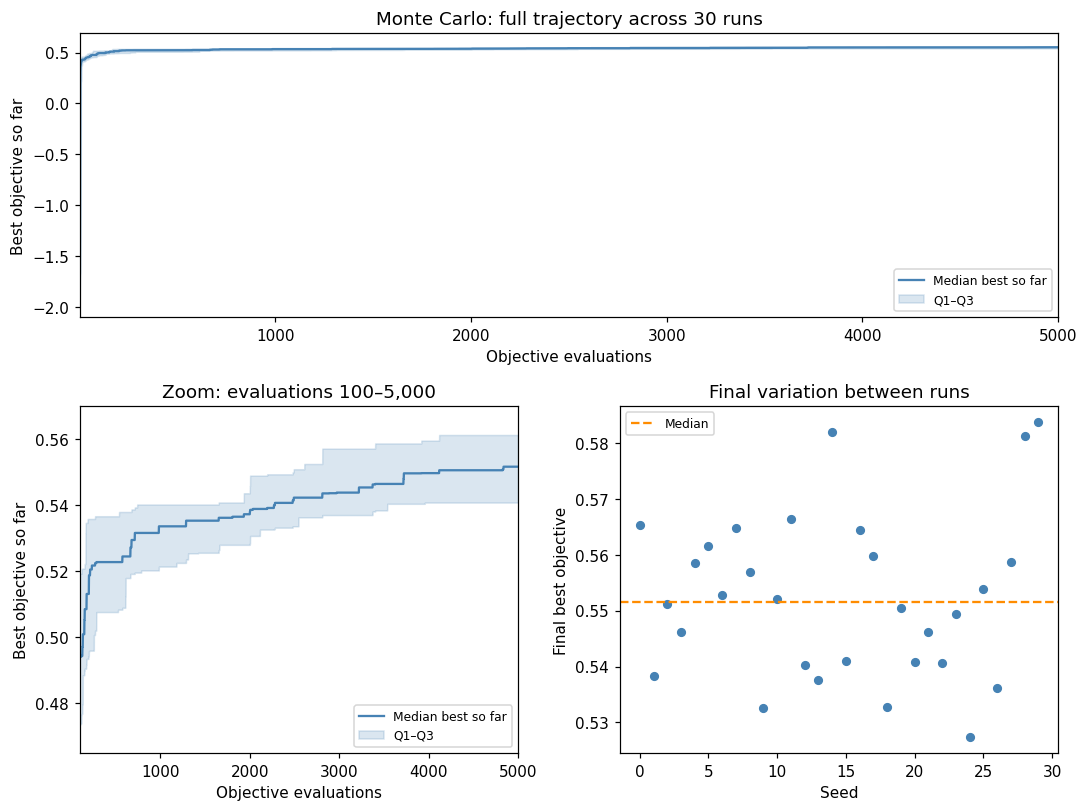

In [16]:
mc_traces = np.array([record.best_so_far for record in mc_records])
trace_q1, trace_median, trace_q3 = np.percentile(mc_traces, [25, 50, 75], axis=0)
evaluations = np.arange(1, BUDGET + 1)
MC_ZOOM_START = 100
zoom = evaluations >= MC_ZOOM_START

fig = plt.figure(figsize=(10, 7.5))
grid = fig.add_gridspec(2, 2, height_ratios=[0.9, 1.1])
full_ax = fig.add_subplot(grid[0, :])
zoom_ax = fig.add_subplot(grid[1, 0])
scores_ax = fig.add_subplot(grid[1, 1])

for ax, mask in ((full_ax, np.ones(BUDGET, dtype=bool)), (zoom_ax, zoom)):
    ax.plot(evaluations[mask], trace_median[mask], color="steelblue", label="Median best so far")
    ax.fill_between(evaluations[mask], trace_q1[mask], trace_q3[mask],
                    color="steelblue", alpha=0.2, label="Q1–Q3")
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8, loc="lower right")

full_ax.set(title="Monte Carlo: full trajectory across 30 runs", xlim=(1, BUDGET))
zoom_low, zoom_high = trace_q1[zoom].min(), trace_q3[zoom].max()
zoom_padding = max(0.005, 0.1 * (zoom_high - zoom_low))
zoom_ax.set(title=f"Zoom: evaluations {MC_ZOOM_START}–{BUDGET:,}",
            xlim=(MC_ZOOM_START, BUDGET),
            ylim=(zoom_low - zoom_padding, zoom_high + zoom_padding))
zoom_ax.ticklabel_format(axis="y", style="plain", useOffset=False)

scores_ax.scatter(SEEDS, mc_scores, color="steelblue", s=25)
scores_ax.axhline(MC_BASELINE_MEDIAN, color="darkorange", linestyle="--", label="Median")
scores_ax.set(xlabel="Seed", ylabel="Final best objective", title="Final variation between runs")
scores_ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Median best at evaluation 100: {trace_median[99]:.6f}")
print(f"Median best at evaluation 1,000: {trace_median[999]:.6f}")
print(f"Median best at evaluation 5,000: {trace_median[-1]:.6f}")
print(f"Runs improving after evaluation 1,000: {np.sum(mc_traces[:, -1] > mc_traces[:, 999])}/{len(SEEDS)}")

### A representative deployment

The illustrated run is the one closest to the median final score. Shaded discs represent sensing coverage, filled markers are active sensors, and thin lines are direct communication links. Marker size no longer encodes power caps in this solution plot.

Representative seed: 10 | objective: 0.552048
Active sensors: 24 | components: 1
Coverage: 0.7718 | energy: 0.2734 | interference: 0.2229


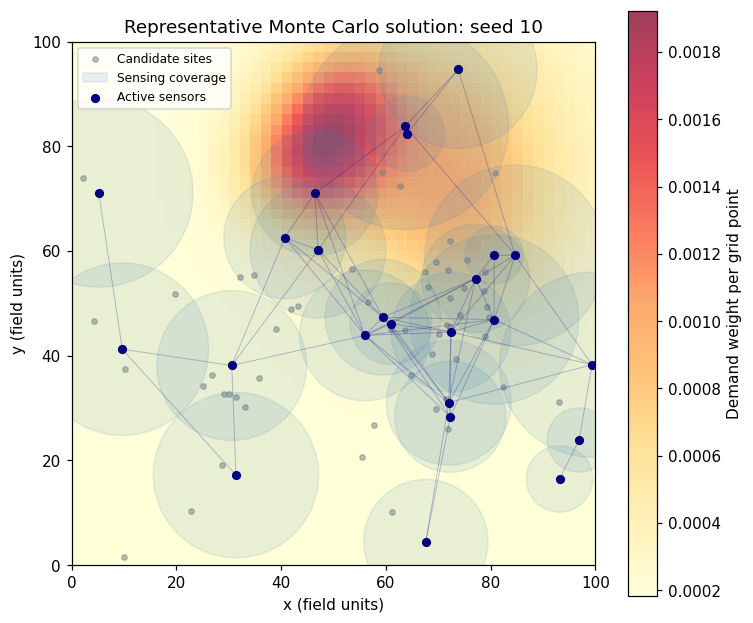

In [17]:
# Select a typical run for illustration, rather than the luckiest run.
mc_rep_index = int(np.argmin(np.abs(mc_scores - MC_BASELINE_MEDIAN)))
mc_rep_seed = SEEDS[mc_rep_index]
rep_active, rep_power, rep_result = mc_solutions[mc_rep_index]

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(instance.demand.reshape(spec.grid_size, spec.grid_size).T,
                  origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.75)
ax.scatter(instance.candidates[:, 0], instance.candidates[:, 1],
           s=12, color="gray", alpha=0.5, label="Candidate sites")

indices = np.flatnonzero(rep_active)
radii = 4 * np.sqrt(rep_power[indices])
for k, site in enumerate(indices):
    ax.add_patch(plt.Circle(instance.candidates[site], radii[k],
                            color="steelblue", alpha=0.12,
                            label="Sensing coverage" if k == 0 else None))
for a in range(len(indices)):
    for b in range(a + 1, len(indices)):
        if instance.dist_between[indices[a], indices[b]] <= 2.5 * min(radii[a], radii[b]):
            xy = instance.candidates[[indices[a], indices[b]]]
            ax.plot(xy[:, 0], xy[:, 1], color="navy", lw=0.6, alpha=0.25)

ax.scatter(instance.candidates[indices, 0], instance.candidates[indices, 1],
           s=25, color="navy", label="Active sensors")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="x (field units)", ylabel="y (field units)",
       aspect="equal", title=f"Representative Monte Carlo solution: seed {mc_rep_seed}")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
fig.tight_layout()
plt.show()

print(f"Representative seed: {mc_rep_seed} | objective: {rep_result.objective:.6f}")
print(f"Active sensors: {rep_result.n_active} | components: {rep_result.n_components}")
print(f"Coverage: {rep_result.coverage:.4f} | energy: {rep_result.energy:.4f} | interference: {rep_result.interference:.4f}")

### Baseline interpretation

The retained final deployment was connected in all 30 runs. Power assignments were sampled within each site's limits, and each run used exactly 5,000 objective evaluations. This establishes a baseline under the declared sampling procedure. It does not imply that every sampled deployment was feasible: disconnected proposals were evaluated with the supplied penalty and consumed the same evaluation budget.

Differences between the worst and best final scores across seeds describe between-run variability, not progressive improvement from one seed to the next. Improvement during search is shown by each run's best-so-far trace. The median trace summarizes those 30 traces at each evaluation count. Its enlarged view reveals additional gains that were visually compressed by the initial negative scores in the full view.

The objective balances demand coverage against energy, redundancy and infeasibility. Neither the number of active sensors nor the objective value alone establishes how much improvement remains, since the optimum is unknown. The median and interquartile range will be compared with other methods under the same budget before judging the baseline's quality and consistency.


In [18]:
print(
    f"Monte Carlo reached a median best objective of {MC_BASELINE_MEDIAN:.4f} "
    f"with Q1–Q3 [{MC_Q1:.4f}, {MC_Q3:.4f}] after {BUDGET:,} evaluations per run. "
    f"The best retained deployment was connected in {mc_feasible_bests}/{len(SEEDS)} runs."
)
print(
    "The low feasible fraction of individual random deployments does not imply "
    "that the best of 5,000 samples is usually disconnected. These are different measurements."
)
print(
    "Keeping the best makes the best-so-far trace nondecreasing, although the "
    "sampling distribution never learns from successful deployments. "
    "Further methods will be compared against this distribution-specific baseline."
)

Monte Carlo reached a median best objective of 0.5516 with Q1–Q3 [0.5407, 0.5612] after 5,000 evaluations per run. The best retained deployment was connected in 30/30 runs.
The low feasible fraction of individual random deployments does not imply that the best of 5,000 samples is usually disconnected. These are different measurements.
Keeping the best makes the best-so-far trace nondecreasing, although the sampling distribution never learns from successful deployments. Further methods will be compared against this distribution-specific baseline.


## Simulated annealing and comparison with Monte Carlo

The same joint engine starts from a random 30%-activation deployment with powers initialized at the selected nominal value, clipped by site caps. At each proposal it flips one bit with probability 0.5 or perturbs one active sensor's power using Gaussian standard deviation 3. An empty deployment forces a bit flip. Powers are clipped into their per-site domains. Unchanged or improving proposals are accepted; a worsening proposal with $\Delta f<0$ is accepted with probability $\exp(\Delta f/T)$ because the problem maximizes.

The current state can worsen, while the separately retained best state cannot. Logs preserve current objective, components, temperature and accepted worsening moves so that the mechanism can be inspected directly.

### Cooling rationale and its limits

The course starting temperatures 0.15 and $10^{-4}$ define a global geometric schedule across 4,999 proposals:

$T_k=T_0(T_f/T_0)^{k/(4999-1)},\qquad k=0,\ldots,4998.$

The measured acceptance of *worsening proposals only* in the first and last 10% of evaluations is reported across the 30 runs, together with denominators. Ties and improvements are excluded from those rates. This is an empirical check of whether the schedule permits early exploration and suppresses late deterioration. Geometric cooling does not inherit the asymptotic global-convergence guarantee associated with appropriately slow logarithmic cooling under its required assumptions. Clipped, state-dependent proposals are used here as a finite-budget heuristic; no equilibrium-sampling or global-optimality guarantee is claimed.

### Paired comparison and schedule diagnostics

The exact joint runs from the coupling study are reused. Monte Carlo and annealing search both layers, but use different sampling and initialization distributions; the comparison assesses the complete configured solvers rather than isolating temperature as a causal factor. Every retained score comes from an evaluated candidate within the budget.

In [19]:
# The joint runs above are exactly the selected standalone SA configuration.
# Reuse them, rather than spending another 150,000 evaluations on identical runs.
sa_scores = joint_scores.copy()
sa_records = joint_records
SA_BASELINE_MEDIAN = float(np.median(sa_scores))
SA_Q1, SA_Q3 = np.percentile(sa_scores, [25, 75])
SA_IQR = float(SA_Q3 - SA_Q1)
assert len(sa_records) == len(SEEDS) == len(mc_records)
assert [r.seed for r in sa_records] == [r.seed for r in mc_records] == list(SEEDS)

save_runset(
    "results/m0_annealing.npz",
    RunSet(algorithm="simulated_annealing", student_id=STUDENT_ID,
           params={**SA_PARAMS, "salt": SALT, "reused_from": "m0_joint"}, records=sa_records),
)
sa_mc_differences = np.round(sa_scores - mc_scores, 12)
sa_mc_test = wilcoxon(sa_mc_differences, alternative="two-sided", method="auto") if np.any(sa_mc_differences) else None
p_sa_vs_mc = float(sa_mc_test.pvalue) if sa_mc_test else 1.0
sa_mc_effect = paired_rank_biserial(sa_scores, mc_scores)
sa_mc_median_difference = float(np.median(sa_scores - mc_scores))
M0_HOLM = holm_correction({"joint_vs_two_stage": p_coupling, "sa_vs_mc": p_sa_vs_mc})

acceptance = [worsening_acceptance(r["log"], BUDGET) for r in joint_results]
early_rates = np.array([a["early_rate"] for a in acceptance])
late_rates = np.array([a["late_rate"] for a in acceptance])
assert np.all(np.isfinite(early_rates)) and np.all(np.isfinite(late_rates))
early_median, late_median = float(np.median(early_rates)), float(np.median(late_rates))
sa_connected_bests = sum(r["result"].feasible for r in joint_results)

print(f"SA median={SA_BASELINE_MEDIAN:.6f}, Q1–Q3=[{SA_Q1:.6f}, {SA_Q3:.6f}], IQR={SA_IQR:.6f}")
print(f"Connected SA best solutions: {sa_connected_bests}/{len(SEEDS)}")
print(f"SA wins/ties/losses vs MC: {(sa_mc_differences > 0).sum()}/{(sa_mc_differences == 0).sum()}/{(sa_mc_differences < 0).sum()}")
print(f"Median paired difference (SA minus MC): {sa_mc_median_difference:+.6f}")
print(f"Wilcoxon raw p={p_sa_vs_mc:.6g}; paired rank-biserial effect={sa_mc_effect:+.4f}")
print(f"Holm-adjusted p-values: {M0_HOLM}")
print(f"Median worsening acceptance: first 10%={early_median:.3f}, last 10%={late_median:.3f}")
print(f"Early worsening proposals per run: {min(a['early_worsening'] for a in acceptance)}–{max(a['early_worsening'] for a in acceptance)}")
print(f"Late worsening proposals per run: {min(a['late_worsening'] for a in acceptance)}–{max(a['late_worsening'] for a in acceptance)}")
print(f"Cooling endpoints: {SA_PARAMS['initial_temperature']} to {SA_PARAMS['final_temperature']}")

SA_REP_INDEX = int(np.argmin(np.abs(sa_scores - SA_BASELINE_MEDIAN)))
sa_rep_log = joint_results[SA_REP_INDEX]["log"]
Path("results").mkdir(exist_ok=True)
np.savez_compressed("results/m0_sa_internal_state.npz", **{
    f"seed_{seed}_{key}": value
    for seed, result in zip(SEEDS, joint_results) for key, value in result["log"].items()
})


SA median=0.714655, Q1–Q3=[0.712220, 0.717910], IQR=0.005690
Connected SA best solutions: 30/30
SA wins/ties/losses vs MC: 30/0/0
Median paired difference (SA minus MC): +0.163040
Wilcoxon raw p=1.86265e-09; paired rank-biserial effect=+1.0000
Holm-adjusted p-values: {'sa_vs_mc': 3.725290298461914e-09, 'joint_vs_two_stage': 0.00011058151721954346}
Median worsening acceptance: first 10%=0.918, last 10%=0.047
Early worsening proposals per run: 199–241
Late worsening proposals per run: 422–462
Cooling endpoints: 0.15 to 0.0001


### Comparative trajectories and internal state

The convergence plots use a common evaluation axis, median trajectories and Q1–Q3. The enlarged view retains evaluations 100–5,000. Paired scatter plots show one point per seed against an equal-score reference.

For the SA run closest to the median final result, the mechanism figure distinguishes accepted current-state quality from best-so-far quality. Marked accepted worsening moves show how temperature allows deterioration while retaining a separate best solution. The component trace describes the accepted current network. These state variables come from the algorithm's own logs, not illustrative animation data.

Representative early/late worsening acceptance: {'early_rate': 0.9004739336492891, 'late_rate': 0.05088495575221239, 'early_worsening': 211, 'late_worsening': 452}
Accepted worsening moves in representative run: 1174


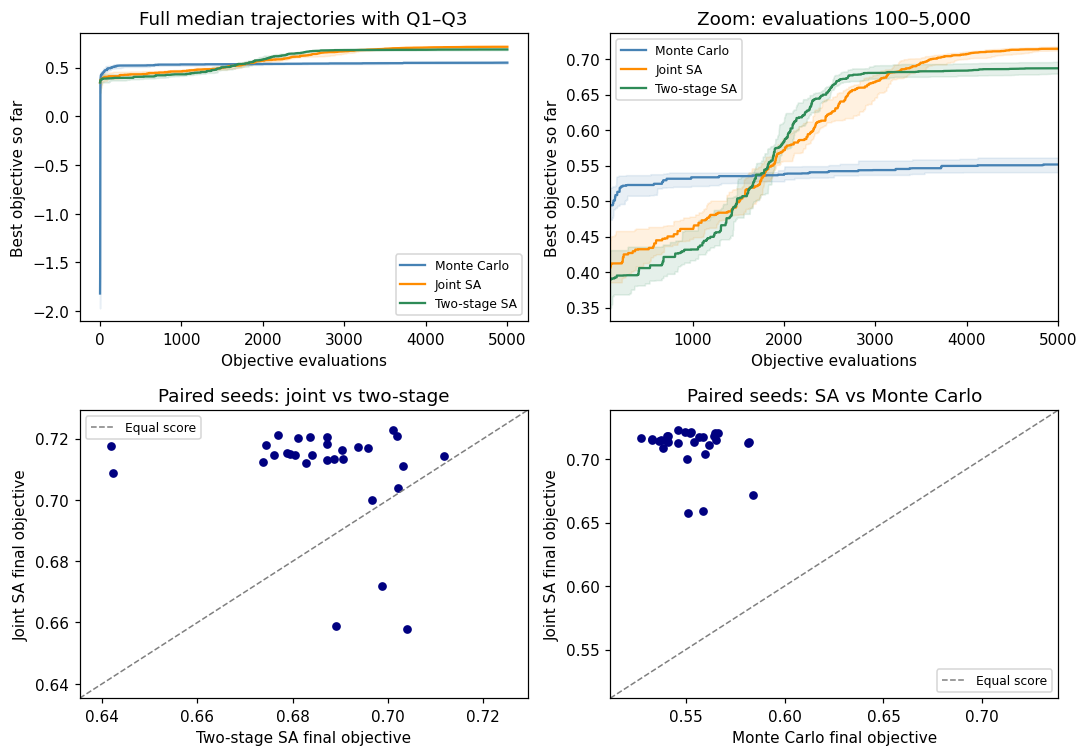

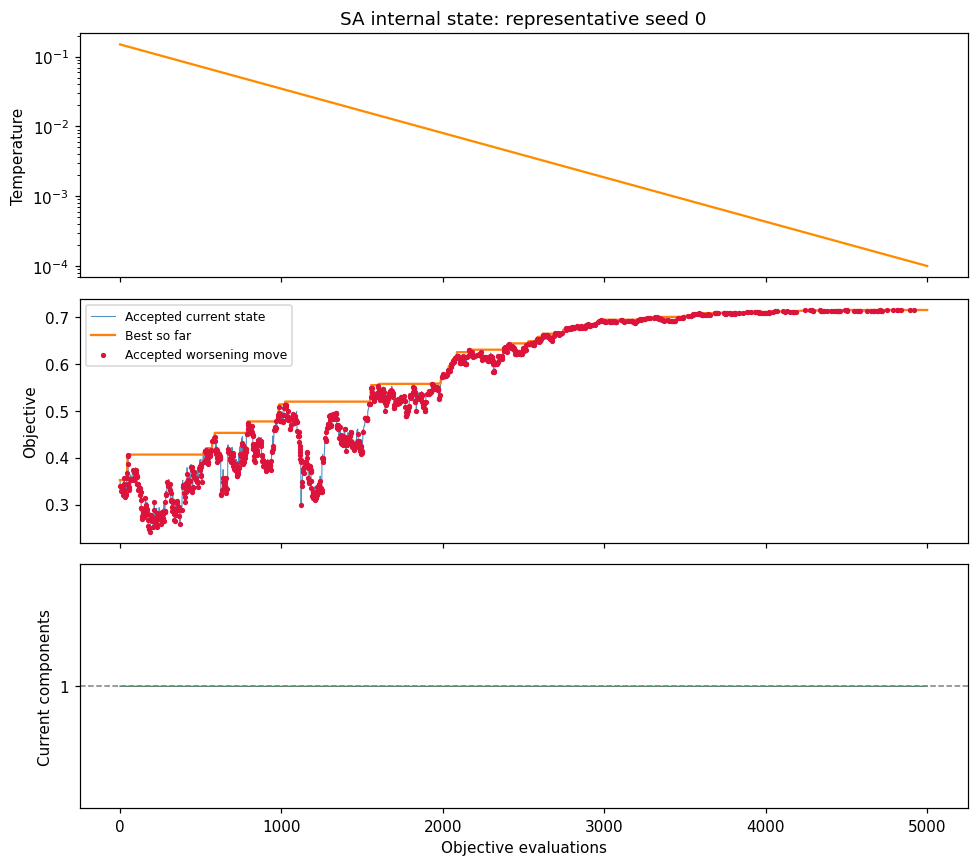

In [20]:
# Both methods are displayed against objective evaluations, not iterations.
sa_traces = np.array([r.best_so_far for r in sa_records])
staged_traces = np.array([r.best_so_far for r in staged_records])
evaluation_axis = np.arange(1, BUDGET + 1)
tail = evaluation_axis >= 100
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tail_limits = []
for traces, label, color in ((mc_traces, "Monte Carlo", "steelblue"),
                             (sa_traces, "Joint SA", "darkorange"),
                             (staged_traces, "Two-stage SA", "seagreen")):
    q1, median, q3 = np.percentile(traces, [25, 50, 75], axis=0)
    for ax, mask in ((axes[0, 0], np.ones(BUDGET, dtype=bool)), (axes[0, 1], tail)):
        ax.plot(evaluation_axis[mask], median[mask], color=color, label=label)
        ax.fill_between(evaluation_axis[mask], q1[mask], q3[mask], color=color, alpha=0.12)
    tail_limits.extend([q1[tail].min(), q3[tail].max()])
for ax in axes[0]:
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8)
axes[0, 0].set_title("Full median trajectories with Q1–Q3")
pad = 0.05 * (max(tail_limits) - min(tail_limits))
axes[0, 1].set(title="Zoom: evaluations 100–5,000", xlim=(100, BUDGET),
                ylim=(min(tail_limits) - pad, max(tail_limits) + pad))

for ax, x, y, xlabel, ylabel in (
    (axes[1, 0], staged_scores, joint_scores, "Two-stage SA final objective", "Joint SA final objective"),
    (axes[1, 1], mc_scores, sa_scores, "Monte Carlo final objective", "Joint SA final objective"),
):
    low, high = min(x.min(), y.min()), max(x.max(), y.max())
    gap = max(0.005, (high - low) * 0.08)
    ax.plot([low - gap, high + gap], [low - gap, high + gap], "--", color="gray", lw=1, label="Equal score")
    ax.scatter(x, y, s=22, color="navy")
    ax.set(xlabel=xlabel, ylabel=ylabel, xlim=(low - gap, high + gap), ylim=(low - gap, high + gap))
    ax.legend(fontsize=8)
axes[1, 0].set_title("Paired seeds: joint vs two-stage")
axes[1, 1].set_title("Paired seeds: SA vs Monte Carlo")
fig.tight_layout()
plt.show()

# The accepted current state is logged separately from evaluated proposals.
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
evaluations_logged = sa_rep_log["evaluation"]
axes[0].plot(evaluations_logged[1:], sa_rep_log["temperature"][1:], color="darkorange")
axes[0].set(yscale="log", ylabel="Temperature", title=f"SA internal state: representative seed {SEEDS[SA_REP_INDEX]}")
axes[1].plot(evaluations_logged, sa_rep_log["current_score"], lw=0.7, alpha=0.8, label="Accepted current state")
axes[1].plot(evaluation_axis, sa_records[SA_REP_INDEX].best_so_far, lw=1.5, label="Best so far")
accepted_worse = sa_rep_log["worsening"] & sa_rep_log["accepted"]
axes[1].scatter(evaluations_logged[accepted_worse], sa_rep_log["current_score"][accepted_worse],
                s=6, color="crimson", label="Accepted worsening move", zorder=3)
axes[1].set_ylabel("Objective")
axes[1].legend(fontsize=8)
axes[2].plot(evaluations_logged, sa_rep_log["components"], lw=0.8, color="seagreen")
axes[2].axhline(1, color="gray", ls="--", lw=1)
max_components = int(sa_rep_log["components"].max())
axes[2].set(xlabel="Objective evaluations", ylabel="Current components",
            yticks=np.arange(1, max_components + 1), ylim=(0.5, max_components + 0.5))
fig.tight_layout()
plt.show()

print(f"Representative early/late worsening acceptance: {acceptance[SA_REP_INDEX]}")
print(f"Accepted worsening moves in representative run: {accepted_worse.sum()}")


## M0 analysis

The problem is difficult because selecting sensors and assigning power affect each other. There are already about 1.21 times 10^24 possible activation subsets before power is considered. In the random-deployment experiment, only 16.5% of 2,000 samples formed a connected network. This percentage describes our sampling procedure, not every possible deployment. The random walk's correlation of 0.935 shows that consecutive objective values were related. It does not establish that finding the optimum is easy, especially because losing connectivity creates a large score penalty.

The two-sensor example demonstrated this interaction directly: the same active sites changed from disconnected to connected when only power changed. The search comparison then asked whether separating the decisions affected the result. Joint search won in 27 of 30 paired seeds and staged search won in three. Their final-score medians were 0.7147 and 0.6872. The median difference within paired seeds was +0.0277 in favor of joint search. Wilcoxon, with Holm correction, provided evidence of a difference between these tested configurations (adjusted p = 0.000111).

Both methods received 5,000 evaluations and the same initial deployment and cooling schedule. Staged search used 2,500 evaluations to choose sensors and 2,500 to tune their power, without reconsidering the subset. Its nominal power of 20 was selected from four candidates using separate tuning seeds and 1,000-evaluation pilot runs. This selection cost 120,000 evaluations and did not use the final comparison seeds.

Annealing also beat Monte Carlo in all 30 paired seeds. Monte Carlo's median was 0.5516, and the median paired advantage of annealing was +0.1630. The adjusted Wilcoxon p-value was 3.73e-09. Annealing explores changes around a current deployment and can accept temporary deterioration, while Monte Carlo keeps drawing independent proposals. Different initializations also contribute to this comparison, so it does not isolate temperature alone.

The median acceptance of worsening proposals fell from 91.8% initially to 4.7% near the end. This supports the intended exploration-to-refinement behavior of the selected cooling schedule, but provides no global-optimality guarantee. The identical joint runs were reused for the annealing comparison, avoiding duplicate evaluations. These findings apply to this instance, budget and configurations. A different stage split, nominal-power pilot, optimizer or instance could change the ordering and would be a useful follow-up test.


### Evaluation accounting

Characterization, deterministic checks, parameter selection and final algorithm comparisons are accounted for separately. The same joint run is used in two comparisons and counted once. All real sensor-placement objective calls pass through the supplied evaluator. The scripted verification objective does not generate experimental results.

In [21]:
M0_EVALUATION_ACCOUNTING = {
    "instance_and_objective_checks": INSTANCE_CHECK_EVALUATIONS,
    "feasibility_characterization": N_DEPLOYMENTS,
    "random_walk": WALK_STEPS + 1,
    "monte_carlo_checks": MC_CHECK_EVALUATIONS,
    "annealing_checks": SA_CHECK_EVALUATIONS,
    "direct_coupling_demonstration": COUPLING_PROBE_EVALUATIONS,
    "nominal_power_tuning": NOMINAL_TUNING_EVALUATIONS,
    "final_monte_carlo_runs": len(SEEDS) * BUDGET,
    "final_joint_annealing_runs": len(SEEDS) * BUDGET,
    "final_two_stage_runs": len(SEEDS) * BUDGET,
}
for name, count in M0_EVALUATION_ACCOUNTING.items():
    print(f"{name:36} {count:>9,}")
print(f"{'Total actual sensor evaluations':36} {sum(M0_EVALUATION_ACCOUNTING.values()):>9,}")
print("Annealing results reused from joint runs: zero additional objective calls.")

instance_and_objective_checks                6
feasibility_characterization             2,000
random_walk                              1,001
monte_carlo_checks                         112
annealing_checks                           231
direct_coupling_demonstration                2
nominal_power_tuning                   120,000
final_monte_carlo_runs                 150,000
final_joint_annealing_runs             150,000
final_two_stage_runs                   150,000
Total actual sensor evaluations        573,352
Annealing results reused from joint runs: zero additional objective calls.


## Carry forward

These computed values pass to M1. Full-precision values remain defined in code; the table summarizes this executed configuration. M1 must explicitly reference `MC_BASELINE_MEDIAN` and `NOMINAL_POWER` by name.

| Quantity / variable | Current value | Purpose |
|---|---:|---|
| `MC_BASELINE_MEDIAN` | 0.551577 | Monte Carlo reference objective |
| `MC_PARAMS["active_fraction_range"]` | (0.1, 0.5) | Baseline sampling distribution |
| `SA_BASELINE_MEDIAN` | 0.714655 | Selected joint annealing result |
| `NOMINAL_POWER` | 20, clipped by site caps | Frozen-power subset search in M1 |
| `SA_PARAMS` | T: 0.15 to 0.0001; step: 3; flip: 0.5; initial activation: 0.3 | Reproduce the selected annealing configuration |
| `BUDGET` | 5,000 per final run | Shared evaluation cap |
| `SEEDS` | 0–29 (30 seeds) | Paired final runs |
| `TUNING_SEEDS` / `TUNING_BUDGET` | 100–129 / 1,000 | Separate nominal-power selection |
| `feasible_fraction` | 0.165 (16.5%) | Random-deployment diagnostic |
| `rho_1` | 0.9353 | Random-walk lag-1 correlation |
| `WALK_POWER_STEP` | 3.0 | Walk perturbation scale |
| `CHAR_SEED` / `WALK_SEED` | 10,000 / 10,001 | Diagnostic reproducibility |
| Characterization / walk evaluations | 2,000 / 1,001 | Separate diagnostic budgets |
| Early / late worsening acceptance, median | 0.918 / 0.047 | Empirical cooling behavior |
| `p_coupling` / Holm-adjusted | 0.000111 / 0.000111 | Joint versus staged comparison |
| `coupling_effect` | +0.759 | Paired rank-biserial effect, joint minus staged |
| `p_sa_vs_mc` / Holm-adjusted | 1.86e-09 / 3.73e-09 | Annealing versus Monte Carlo |
| `sa_mc_effect` | +1.000 | Paired rank-biserial effect, SA minus MC |

The table and analysis reflect the current parameters and instance. Refresh them if experiments change. M0 interpretation and AI-ledger verdicts remain subject to student review.


In [22]:
M0_DIAGNOSTICS = {
    "characterization_seed": CHAR_SEED,
    "walk_seed": WALK_SEED,
    "feasible_fraction": feasible_fraction,
    "rho_1": rho_1,
    "walk_power_step": WALK_POWER_STEP,
    "characterization_evaluations": characterization.evaluations_used,
    "walk_evaluations": walk_problem.evaluations_used,
}
M0_CARRY_FORWARD = {
    "MC_BASELINE_MEDIAN": MC_BASELINE_MEDIAN,
    "MC_PARAMS": MC_PARAMS,
    "NOMINAL_POWER": NOMINAL_POWER,
    "SA_PARAMS": SA_PARAMS,
    "SA_BASELINE_MEDIAN": SA_BASELINE_MEDIAN,
    "p_sa_vs_mc": p_sa_vs_mc,
    "p_coupling": p_coupling,
    "M0_HOLM": M0_HOLM,
    "coupling_effect": coupling_effect,
    "sa_mc_effect": sa_mc_effect,
}
print(M0_DIAGNOSTICS)
print(M0_CARRY_FORWARD)


{'characterization_seed': 10000, 'walk_seed': 10001, 'feasible_fraction': 0.165, 'rho_1': 0.9352701174413995, 'walk_power_step': 3.0, 'characterization_evaluations': 2000, 'walk_evaluations': 1001}
{'MC_BASELINE_MEDIAN': 0.5515770165919147, 'MC_PARAMS': {'active_fraction_range': (0.1, 0.5)}, 'NOMINAL_POWER': 20.0, 'SA_PARAMS': {'initial_temperature': 0.15, 'final_temperature': 0.0001, 'power_step': 3.0, 'flip_probability': 0.5, 'active_fraction': 0.3, 'nominal_power': 20.0}, 'SA_BASELINE_MEDIAN': 0.7146553510068925, 'p_sa_vs_mc': 1.862645149230957e-09, 'p_coupling': 0.00011058151721954346, 'M0_HOLM': {'sa_vs_mc': 3.725290298461914e-09, 'joint_vs_two_stage': 0.00011058151721954346}, 'coupling_effect': 0.7591397849462366, 'sa_mc_effect': 1.0}


# M1


# M2


# M3


# Analysis


# AI Ledger


This ledger is updated as the work progresses. Entries describe actual assistance;
the student's final acceptance and interpretation remain pending review.

| Tool / model | Prompt or task | Output | Verdict | Verification |
|---|---|---|---|---|
| ChatGPT / Codex; model identifier not independently verified in the notebook | Continue the uploaded sensor-placement notebook with formulation and initial M0 characterization. | Formulation, instance map, random-deployment sampling and an unconditional random walk. | Pending student review. | Independent single-sensor calculation; disconnected-pair penalty; power-cap equivalence; deterministic instance regeneration; batch and over-budget checks. Exact diagnostic counts are asserted in code. |

| ChatGPT / Codex; model identifier not independently verified in the notebook | Continue with the Monte Carlo baseline, retaining the revised preliminary interpretation. | Budget-limited random search, 30-seed study, summaries and representative deployment. | Pending student review. | Independent replay, retained-vector check, seeded repeatability and exact per-run budget assertions; executed results are reported in M0. |

| ChatGPT / Codex; model identifier not independently verified in the notebook | Implement and verify annealing, then compare joint and staged search. | Reusable SA engine, disjoint-seed nominal-power pilot, controlled connectivity demonstration, paired experiments and diagnostics. | Pending student review. | Scripted acceptance/rejection, exact cooling endpoints, fixed-layer audits, one-counter stage accounting, common-start and temperature checks; numerical results are reported in M0. |

At least one concrete AI error, its evidence and correction still need to be
documented. No error or student acceptance is fabricated here.

### Observed AI error: equation formatting

- **Output:** the assistant-generated annealing explanation omitted LaTeX backslashes, leaving `$Delta f<0$`, `$exp(Delta f/T)$`, `qquad` and `ldots` in the notebook source.
- **Evidence:** these malformed expressions were present in commit `5916413`; the acceptance implementation itself still used `np.exp(delta / temperature)`.
- **Correction:** restored the missing mathematical commands in the explanatory Markdown.
- **Verification:** checked the corrected source strings and confirmed that all code cells, execution counts and outputs remained identical.
- **Verdict:** modified by the assistant; student review is pending. This is a presentation error, not an experimentally observed defect in the optimizer.



# Video